In [27]:
import pandas as pd
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor


In [28]:
df = pd.read_csv(r"C:\Users\carla\OneDrive\Documentos\analisis de datos\CSVS\Boston_examen.csv")

In [29]:
df

,Unnamed: 0,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,502,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4
502,503,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6
503,504,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9
504,505,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0


In [30]:
df.isna().sum()

Unnamed: 0    0
crim          0
zn            0
indus         0
chas          0
nox           0
rm            0
age           0
dis           0
rad           0
tax           0
ptratio       0
lstat         0
medv          0
dtype: int64

In [31]:
df["rm2"] = df["rm"]**2
df["lstat2"] = df["lstat"]**2
df["rm_lstat"] = df["rm"] * df["lstat"]


In [32]:
target = 'medv'
X = df.copy()
del X[target]
del X["Unnamed: 0"]
y = df[target]

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

In [34]:
predicciones_bivariadas = {}
coeficientes_y_R2=[]

for col in X.columns:
    
    X_temp_train = X_train[[col]]
    X_temp_test = X_test[[col]]

    model = LinearRegression()
    model.fit(X_temp_train, y_train)

    y_predict = model.predict(X_temp_test)
    R2=r2_score(y_test, y_predict)
    coeficientes_y_R2.append({
        "variable" :col,
        "coeficiente" : model.coef_[0],
        "intercepto": model.intercept_,
        "R2": R2
    })
    # Guardamos cada modelo como columna
    predicciones_bivariadas[f"biv_{col}"] = y_predict
df_biv_lineales= pd.DataFrame(coeficientes_y_R2)
df_biv_lineales


,variable,coeficiente,intercepto,R2
0,crim,-0.404388,24.142292,0.176457
1,zn,0.132538,21.121231,0.144961
2,indus,-0.635013,29.825693,0.236939
3,chas,9.066476,22.139407,-0.013823
4,nox,-33.841355,41.478242,0.186436
5,rm,9.580926,-37.837259,0.441522
6,age,-0.118682,30.822695,0.160248
7,dis,0.996295,18.908444,0.069214
8,rad,-0.426326,26.743946,0.130037
9,tax,-0.026136,33.318119,0.215605


In [35]:
modelo = LinearRegression().fit(X_train,y_train)

lineal_multiv= modelo.predict(X_test)

r2_score(y_true=y_test, y_pred=lineal_multiv)

0.7485498243502358

In [36]:
pipeline2 = Pipeline([
    ("poly", PolynomialFeatures(degree=2)),
    ("scaler", StandardScaler()),
    ("model", linear_model.LinearRegression())
])
pipeline2.fit(X_train, y_train)
predicciones_poly2 = pipeline2.predict(X_test)
r2_score(y_true=y_test,y_pred=predicciones_poly2)

0.2503669654855606

In [37]:
pipeline3 = Pipeline([
    ("poly", PolynomialFeatures(degree=3)),
    ("scaler", StandardScaler()),
    ("model", linear_model.LinearRegression())
])
pipeline3.fit(X_train, y_train)

predicciones_poly3 = pipeline3.predict(X_test)
r2_score(y_true=y_test,y_pred=predicciones_poly3)

-33.77503848583146

In [38]:
pipeline4 = Pipeline([
    ("poly", PolynomialFeatures(degree=4)),
    ("scaler", StandardScaler()),
    ("model", linear_model.LinearRegression())
])
pipeline4.fit(X_train, y_train)

predicciones_poly4 = pipeline4.predict(X_test)
r2_score(y_true=y_test,y_pred=predicciones_poly4)

-21.560294245029397

In [39]:
pipeline_ridge = Pipeline([
   ( "poly", PolynomialFeatures()),
   ("scaler", StandardScaler()),
    ("ridge", Ridge())
 ])

params = {
    "poly__degree": [2,3,4], 
    "ridge__alpha": np.logspace(-4,4,10), 
        }
# Grid search
grid_ridge= GridSearchCV(estimator=pipeline_ridge, param_grid=params, cv=5, scoring="r2", n_jobs=-1)
grid_ridge.fit(X_train, y_train)
predicciones_ridge = grid_ridge.predict(X_test)
r2_score(y_true=y_test,y_pred=predicciones_ridge)

0.7777449113344821

In [40]:
grid_ridge.best_params_

{'poly__degree': 2, 'ridge__alpha': np.float64(21.54434690031882)}

In [41]:
pipeline_KNN= Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor())
])
params={"model__n_neighbors": np.arange(1,59)}
grid_KNN=GridSearchCV(estimator=pipeline_KNN, cv=5, scoring="r2",param_grid=params)
grid_KNN.fit(X_train , y_train)
predicciones_KNN=grid_KNN.predict(X_test)
r2_score(y_true=y_test,y_pred=predicciones_KNN)

0.7209108497028665

In [42]:
grid_KNN.best_params_

{'model__n_neighbors': np.int64(4)}

In [43]:
predicciones= pd.DataFrame({ 
    "real": y_test,
    "knn": predicciones_KNN,
    "lineal_multivariado": lineal_multiv,
    "ridge": predicciones_ridge,
    "poly2": predicciones_poly2,
    "poly3": predicciones_poly3,
    "poly4": predicciones_poly4,
    **predicciones_bivariadas #desarmar las columnas
})

In [44]:
predicciones

,real,knn,lineal_multivariado,ridge,poly2,poly3,poly4,biv_crim,biv_zn,biv_indus,...,biv_rm,biv_age,biv_dis,biv_rad,biv_tax,biv_ptratio,biv_lstat,biv_rm2,biv_lstat2,biv_rm_lstat
173,23.6,26.150,25.487808,25.760359,26.408224,27.370369,28.650438,24.105178,21.121231,27.253892,...,23.633962,20.841543,21.544939,24.612317,25.581923,26.466440,26.219079,23.269057,25.950824,25.982964
274,32.4,34.875,37.085242,33.685005,25.629714,29.126612,40.742484,24.119469,26.422740,25.755263,...,26.910639,26.918059,22.970936,25.038643,26.679626,24.295636,31.659171,26.706670,27.708715,32.006826
491,13.6,16.100,13.940139,14.927400,15.217029,39.904706,29.522362,24.099532,21.121231,12.210446,...,19.485421,19.096919,20.769623,25.038643,14.735567,18.868626,17.303647,19.172795,19.737527,17.142148
72,22.8,23.000,25.230363,25.152000,19.669360,10.586002,10.872908,24.105234,21.121231,22.961208,...,20.271057,29.896976,24.176155,25.038643,25.346701,20.822350,29.694419,19.926570,27.251620,30.309121
452,16.1,17.675,16.447204,16.108666,15.542102,16.122371,16.785118,22.083889,21.121231,18.331966,...,22.493832,19.927692,21.267870,16.512129,15.911678,18.651546,18.093497,22.114785,20.455092,17.029878
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,19.3,19.525,18.650029,18.878619,19.582264,13.515844,15.479247,24.056720,21.121231,24.389986,...,20.960884,20.449893,21.613086,24.612317,23.281973,17.131983,21.874904,20.596882,23.440361,21.664077
81,23.9,26.300,25.910638,25.046955,25.025796,-16.185264,-1.386458,24.124248,24.434675,26.739532,...,25.578890,22.467486,24.289134,25.038643,25.973960,21.256510,28.015987,25.287982,26.701923,27.784476
38,24.7,23.675,22.114382,22.952734,21.797125,27.313862,25.660419,24.071504,21.121231,26.041018,...,19.322546,27.238500,22.741490,24.612317,26.026231,20.822350,25.142908,19.017808,25.420486,25.553391
317,19.8,19.500,17.360615,17.524146,16.404833,23.351718,13.403640,24.043128,21.121231,23.539069,...,17.559655,22.313199,22.925207,25.038643,25.372836,22.558993,19.406622,17.368526,21.576143,19.955655


In [45]:
predicciones["bins"] = pd.qcut(predicciones["real"], q=10, labels=False)
bivariado = predicciones.groupby("bins").mean()

CONCLUSIONES
de peor a mejor

Text(0, 0.5, 'Real')

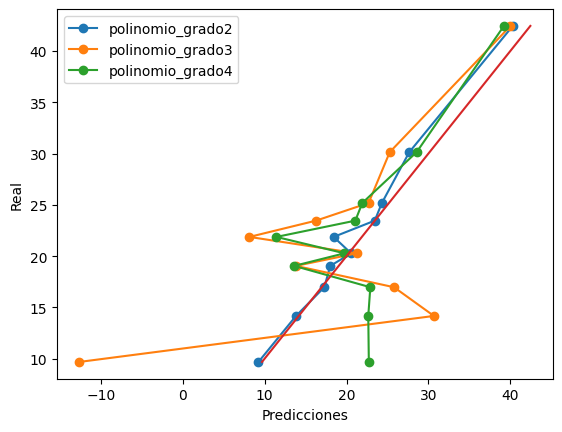

In [46]:
plt.plot(bivariado.poly2, bivariado.real, label="polinomio_grado2", marker="o")
plt.plot(bivariado.poly3, bivariado.real, label="polinomio_grado3", marker="o")
plt.plot(bivariado.poly4, bivariado.real, label="polinomio_grado4", marker="o")
plt.plot(bivariado.real,bivariado.real)
plt.legend()
plt.xlabel("Predicciones")
plt.ylabel("Real")

Las regresiones polinomiales muestran un desempeño deficiente en general. El mejor ajuste de est tipo se obtiene con el polinomio de grado 2 (R2=0.25), ya que este grado todavía mantiene un nivel de complejidad razonable para el tamaño del conjunto de entrenamiento. Sin embargo, al aumentar el grado a 3 y 4, el R2 se vuelve negativo, lo que indica que el modelo predice peor que simplemente utilizar la media de la variable objetivo.

Este comportamiento se explica por el incremento exponencial en el número de variables generadas al elevar el grado del polinomio. Al introducir demasiadas características en relación con la cantidad de datos disponibles, el modelo se vuelve excesivamente flexible y comienza a ajustar el ruido del conjunto de entrenamiento en lugar de la estructura real del fenómeno. Como consecuencia, se produce un fuerte overfitting, lo que deteriora gravemente la capacidad predictiva en el conjunto de prueba: aumentar la complejidad del modelo dandole completa libertad de ajuste y sin regularización conduce a una pérdida de capacidad de generalización, evidenciando que un mayor grado polinomial no necesariamente implica un mejor desempeño predictivo.

Text(0, 0.5, 'Real')

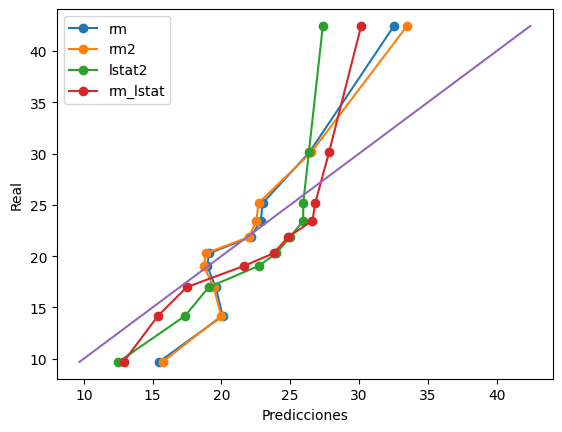

In [51]:
plt.plot(bivariado.biv_rm, bivariado.real, label="rm", marker="o")
plt.plot(bivariado.biv_rm2, bivariado.real, label="rm2", marker="o")
plt.plot(bivariado.biv_lstat2, bivariado.real, label="lstat2", marker="o")
plt.plot(bivariado.biv_rm_lstat, bivariado.real, label="rm_lstat", marker="o")
plt.plot(bivariado.real,bivariado.real)
plt.legend()
plt.xlabel("Predicciones")
plt.ylabel("Real")

Los modelos bivariados no presentaron resultados desastrosos porque algunas variables individuales sí mantienen una relación parcial con la variable objetivo. En particular, variables como lstat, rm o algunas transformaciones cuadráticas muestran cierta linealidad con medv, y explica una parte de la variabilidad del fenómeno. Esto se refleja en que sus predicciones no se alejan completamente de la línea de referencia.

Sin embargo, su capacidad predictiva es limitada porque cada modelo utiliza únicamente una variable explicativa. En un problema como este, el valor objetivo depende simultáneamente de múltiples factores que al modelar cada variable por separado, se ignora la interacción y el efecto conjunto entre ellas, lo que reduce significativamente el poder explicativo: aunque ciertos modelos bivariados tuvieron un desempeño relativamente aceptable, ninguno logra capturar adecuadamente la dinámica global del fenómeno y por qué el R2 es moderado o bajo en comparación con modelos más completos.

El análisis multivariado es superior porque permite incorporar simultáneamente múltiples variables, capturando efectos combinados, compensaciones e interacciones implícitas. Al considerar la información conjunta del sistema, se reduce el sesgo por omisión de variables relevantes y se mejora tanto la capacidad predictiva como la estabilidad del modelo. En consecuencia, el modelo multivariado ofrece una representación más realista y robusta del proceso generador de datos.

Text(0, 0.5, 'Real')

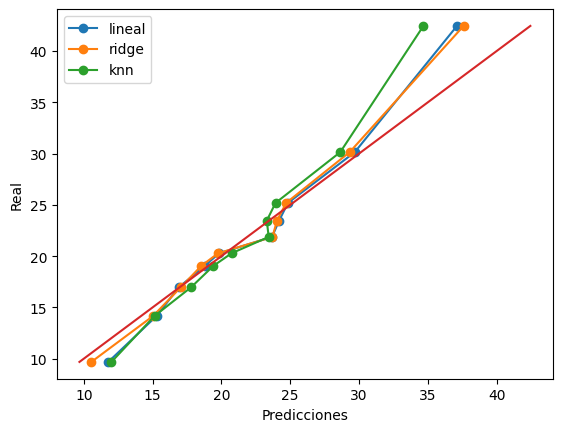

In [50]:
plt.plot(bivariado.lineal_multivariado, bivariado.real, label="lineal", marker="o")
plt.plot(bivariado.ridge, bivariado.real, label="ridge", marker="o")
plt.plot(bivariado.knn, bivariado.real, label="knn", marker="o")
plt.plot(bivariado.real,bivariado.real)
plt.legend()
plt.xlabel("Predicciones")
plt.ylabel("Real")

1- REGRESION RIDGE: 0.7777449113344821
El modelo Ridge obtuvo el mejor desempeño entre los evaluados, la incorporación de regularización permitió controlar la magnitud de los coeficientes, reduciendo el riesgo de sobreajuste y mejorando la capacidad de generalización en el conjunto de prueba. Al penalizar la complejidad del modelo, Ridge logra un equilibrio entre ajuste y estabilidad, lo que explica su mayor R2 en comparación con la regresión lineal estándar. No me sorprende que haya sido el modelo ganador, basicamente perfecciona la regresion lineal manteniendo las multiples varibales para explicar una tendencia y logra un gran balance entre polinomios que le agregan complejidad y que a la vez reeajusta las descompensaciones de sus coeficientes para corregir el OFERTITING.

2-REGRESION LINEAL MULTIVARIADA: 0.7485498243502358
La regresión lineal multivariada mostró un desempeño sólido al incorporar simultáneamente todas las variables, su capacidad para capturar el efecto conjunto de los predictores permitió modelar adecuadamente la tendencia general del fenómeno, reflejándose en un buen alineamiento con los datos de test, aunque asume relaciones lineales entre las variables y la respuesta, logra una representación estable y consistente, lo que confirma que una combinación lineal de múltiples factores explica una parte significativa de la variabilidad del precio.

3- KNN: 0.7209108497028665
El modelo KNN a pesar de ser un modelo tan sencillo presentó un desempeño competitivo, su enfoque no paramétrico le permite adaptarse a patrones locales en los datos sin asumir una estructura funcional específica, KNN puede ser un gran predictor, pero depende mucho del dataset y la distribucion de sus datos, aun así, logró capturar adecuadamente la tendencia general, mostrando que la información espacial entre observaciones contiene suficiente señal predictiva.

El análisis comparativo de los distintos modelos permitió comprender tanto la estructura del dataset como el comportamiento de la variable objetivo medv que representa el valor mediano de las viviendas. Los modelos bivariados mostraron que algunas variables individuales tienen capacidad explicativa parcial, lo que confirma que existen relaciones directas entre ciertos factores estructurales o socioeconómicas y el precio de la vivienda. Sin embargo, su poder predictivo es limitado, ya que al considerar cada variable de manera aislada se omite el efecto conjunto e interacción entre múltiples dimensiones del entorno urbano.

Las regresiones polinomiales evidenciaron que aumentar excesivamente la complejidad del modelo no mejora necesariamente el desempeño. Mientras que el polinomio de grado 2 logró un ajuste moderado, los grados 3 y 4 generaron R2 negativos, lo que indica sobreajuste y pobre capacidad de generalización. Esto sugiere que el comportamiento del precio mediano de las viviendas no está dominado por relaciones altamente no lineales de alto orden, sino por una estructura más estable y combinada entre variables. En otras palabras, el fenómeno no requiere una complejidad extrema, sino una modelación balanceada.

El mejor desempeño fue obtenido por el modelo Ridge, lo que indica que el precio mediano de vivienda depende simultáneamente de múltiples factores y que existe cierto grado de colinealidad entre ellos. La regularización permitió controlar la magnitud de los coeficientes, reducir la varianza del modelo y mejorar su capacidad de generalización. Esto confirma que el precio mediano de las viviendas es una variable multicausal, influida por características físicas de las viviendas, factores socioeconómicos, infraestructura y entorno urbano.

En conjunto, los resultados muestran que el dataset presenta una estructura predominantemente multivariada y mayormente lineal en términos combinados. La variable medv no puede explicarse adecuadamente mediante un único predictor ni mediante modelos excesivamente complejos, sino mediante un enfoque que integre múltiples dimensiones con control de complejidad. 
